# Diagnostic Linear Regression for EPVI Targets

This notebook fits a deliberately simple linear baseline to diagnose how much of each EPVI target can be explained by the constructed satellite-derived indices alone.

The notebook uses the saved spatial split from `data/spatial_split_assignments.csv`:

- hyperparameter/model diagnostics use the saved spatial-CV folds on the training regions;
- the fixed test set is used only for final held-out evaluation;
- predictors are restricted to satellite-derived constructed indices so standardized coefficients can be read as a rough importance diagnostic.


In [ ]:
from __future__ import annotations

from importlib import import_module, reload
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)

try:
    from IPython.display import display
except Exception:
    display = print

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline" / "config").exists())
sys.path.append(str(REPO_ROOT))

from pipeline.utils.paths import load_paths, path_value, repo_data_path

rf_utils = reload(import_module("pipeline.3_epvi_prediction.utils"))
PATHS = load_paths()
SAT_CSV = PATHS["outputs_indices_dir"] / "freguesia_indices_streaming.csv"
ADM_CSV = repo_data_path("all_used_adm_indicators.csv")
ADM_SPLIT_JSON = repo_data_path("adm_data_split.json")
NUTS3_MAPPING_CSV = repo_data_path("freguesias_to_NUTS3.csv")
SPATIAL_SPLIT_ASSIGNMENTS_CSV = repo_data_path("spatial_split_assignments.csv")
EPVI_CSV = PATHS["epvi_csv"]

EXCLUDE_OVERSEAS_TERRITORIES = False
OVERSEAS_NUTS3 = tuple(rf_utils.OVERSEAS_NUTS3)
MODEL_SCOPE_LABEL = "mainland_only" if EXCLUDE_OVERSEAS_TERRITORIES else "all_territories"

print("repo:", REPO_ROOT)
print("satellite predictors:", SAT_CSV)
print("private EPVI targets:", EPVI_CSV)
print("saved spatial split assignments:", SPATIAL_SPLIT_ASSIGNMENTS_CSV)
print("model scope:", MODEL_SCOPE_LABEL)


repo: E:\git_projects\energy_poverty_from_space
satellite predictors: E:\OneDrive\Studia\Studia magisterskie\Masterarbeit 2 - Sozialwissenschaften\data\outputs\indices\freguesia_indices_streaming.csv
private EPVI targets: E:\OneDrive\Studia\Studia magisterskie\Masterarbeit 2 - Sozialwissenschaften\data\EPVI_results_gouveia_et_al_2019.csv
saved spatial split assignments: E:\git_projects\energy_poverty_from_space\data\spatial_split_assignments.csv
model scope: all_territories


## Load Inputs and Saved Split

The table is built with the same utility functions as the random-forest notebook. We retain only satellite-derived predictors for this diagnostic model.


In [2]:
inputs = rf_utils.load_prediction_inputs(
    sat_csv=SAT_CSV,
    adm_csv=ADM_CSV,
    epvi_csv=EPVI_CSV,
    adm_split_json=ADM_SPLIT_JSON,
)
EPVI_TARGETS = inputs["targets"]

model_df, _, constant_cols_initial = rf_utils.build_modeling_table(inputs)
nuts3_mapping = rf_utils.load_nuts3_mapping(NUTS3_MAPPING_CSV)
model_df = rf_utils.attach_nuts3(model_df, nuts3_mapping)

if EXCLUDE_OVERSEAS_TERRITORIES:
    before = len(model_df)
    model_df = model_df.loc[~model_df["NUTS3"].isin(OVERSEAS_NUTS3)].copy()
    print(f"Excluded {before - len(model_df)} overseas rows.")

split_assignments = rf_utils.load_spatial_split_assignments(SPATIAL_SPLIT_ASSIGNMENTS_CSV)
model_df, train_df, test_df = rf_utils.apply_spatial_split_assignments(model_df, split_assignments)

sat_cols = [c for c in inputs["sat_cols"] if c in model_df.columns]
constant_sat_cols = [c for c in sat_cols if model_df[c].nunique(dropna=True) <= 1 or model_df[c].notna().sum() == 0]
sat_predictor_cols = [c for c in sat_cols if c not in constant_sat_cols]

print("targets:", EPVI_TARGETS)
print("model rows:", len(model_df))
print("training rows:", len(train_df))
print("fixed test rows:", len(test_df))
print("satellite predictors used:", len(sat_predictor_cols))
print("dropped constant/all-missing satellite predictors:", constant_sat_cols)
print("test NUTS3:", sorted(test_df["NUTS3"].unique()))
display(train_df.groupby("spatial_cv_fold").size().rename("training_cv_fold_rows").to_frame())
display(model_df[sat_predictor_cols].isna().mean().sort_values(ascending=False).head(20).rename("missing_share").to_frame())


targets: ['EPG heating', 'EPG cooling', 'AIAM', 'EPVI heating', 'EPVI cooling']
model rows: 3092
training rows: 2519
fixed test rows: 573
satellite predictors used: 44
dropped constant/all-missing satellite predictors: ['res_vol_per_capita_p10', 'pop_density_p10', 'ntl_per_res_vol_p10', 'ntl_per_res_vol_p50', 'energy_per_vol_per_capita_p10']
test NUTS3: ['PT112', 'PT16J', 'PT185', 'PT187']


,training_cv_fold_rows
spatial_cv_fold,
0,507
1,500
2,467
3,547
4,498


,missing_share
extreme_cold,0.106080
extreme_heat,0.106080
cdd_25,0.106080
hdd_18,0.106080
standard_delta_pm_25,0.017141
energy_per_vol_per_capita,0.017141
ntl_per_res_vol_p90,0.017141
ntl_per_res_vol_gini,0.017141
energy_per_vol_per_capita_p50,0.017141
energy_per_vol_per_capita_p90,0.017141


## Fit Linear Baseline

The main diagnostic model is ordinary least squares with median imputation and standardized predictors. Because predictors are standardized, coefficient magnitudes are comparable across indices.

A RidgeCV variant is also fit as a stability check. The coefficient ranking below uses OLS unless otherwise noted.


In [ ]:
def rmse(y_true, y_pred):
    return rf_utils.rmse(y_true, y_pred)


def spearman(y_true, y_pred):
    return rf_utils.spearman_corr(y_true, y_pred)


def metric_row(prefix, y_true, y_pred):
    return {
        f"{prefix}_r2": r2_score(y_true, y_pred),
        f"{prefix}_mae": mean_absolute_error(y_true, y_pred),
        f"{prefix}_rmse": rmse(y_true, y_pred),
        f"{prefix}_spearman": spearman(y_true, y_pred),
    }


def make_ols_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ])


def make_ridge_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", RidgeCV(alphas=np.logspace(-3, 4, 50))),
    ])

metrics = []
coef_frames = []
pred_frames = []
ridge_metrics = []

for target in EPVI_TARGETS:
    train_t = train_df.dropna(subset=[target]).copy().reset_index(drop=True)
    test_t = test_df.dropna(subset=[target]).copy().reset_index(drop=True)
    spatial_cv, fold_summary = rf_utils.make_precomputed_cv_splits(train_t, fold_col="spatial_cv_fold")

    X_train = train_t[sat_predictor_cols]
    y_train = train_t[target].astype(float)
    X_test = test_t[sat_predictor_cols]
    y_test = test_t[target].astype(float)

    ols = make_ols_pipeline()
    cv_pred = cross_val_predict(ols, X_train, y_train, cv=spatial_cv, n_jobs=-1)
    ols.fit(X_train, y_train)
    train_pred = ols.predict(X_train)
    test_pred = ols.predict(X_test)

    row = {
        "target": target,
        "model": "OLS standardized satellite indices",
        "model_scope": MODEL_SCOPE_LABEL,
        "n_train_rows": len(train_t),
        "n_test_rows": len(test_t),
        "n_predictors": len(sat_predictor_cols),
        **metric_row("train_spatial_cv", y_train, cv_pred),
        **metric_row("train_in_sample", y_train, train_pred),
        **metric_row("fixed_test", y_test, test_pred),
    }
    metrics.append(row)

    coefs = ols.named_steps["model"].coef_
    coef_frames.append(pd.DataFrame({
        "target": target,
        "feature": sat_predictor_cols,
        "standardized_coef": coefs,
        "abs_standardized_coef": np.abs(coefs),
    }).sort_values("abs_standardized_coef", ascending=False))

    for role, data, observed, predicted in [
        ("train_spatial_cv", train_t, y_train, cv_pred),
        ("train_in_sample", train_t, y_train, train_pred),
        ("fixed_test", test_t, y_test, test_pred),
    ]:
        pred_frames.append(pd.DataFrame({
            "target": target,
            "prediction_role": role,
            "ID_norm": data["ID_norm"],
            "NUTS3": data["NUTS3"],
            "name": data["parish_name"],
            "observed": observed,
            "predicted": predicted,
            "residual": observed - predicted,
        }))

    ridge = make_ridge_pipeline()
    ridge_cv_pred = cross_val_predict(ridge, X_train, y_train, cv=spatial_cv, n_jobs=-1)
    ridge.fit(X_train, y_train)
    ridge_test_pred = ridge.predict(X_test)
    ridge_metrics.append({
        "target": target,
        "model": "RidgeCV standardized satellite indices",
        "alpha": ridge.named_steps["model"].alpha_,
        **metric_row("train_spatial_cv", y_train, ridge_cv_pred),
        **metric_row("fixed_test", y_test, ridge_test_pred),
    })

metrics_df = pd.DataFrame(metrics)
ridge_metrics_df = pd.DataFrame(ridge_metrics)
coef_df = pd.concat(coef_frames, ignore_index=True)
predictions_df = pd.concat(pred_frames, ignore_index=True)

display(metrics_df.sort_values("fixed_test_r2", ascending=False))
print("Ridge stability check:")
display(ridge_metrics_df.sort_values("fixed_test_r2", ascending=False))


,target,model,model_scope,n_train_rows,n_test_rows,n_predictors,train_spatial_cv_r2,train_spatial_cv_mae,train_spatial_cv_rmse,train_spatial_cv_spearman,train_in_sample_r2,train_in_sample_mae,train_in_sample_rmse,train_in_sample_spearman,fixed_test_r2,fixed_test_mae,fixed_test_rmse,fixed_test_spearman
4,EPVI cooling,OLS standardized satellite indices,all_territories,2519,573,44,0.233606,0.547614,0.700199,0.470160,0.436696,0.466929,0.600298,0.629276,0.373809,0.438369,0.558348,0.617029
1,EPG cooling,OLS standardized satellite indices,all_territories,2519,573,44,0.168752,0.768390,0.992742,0.397296,0.493324,0.587975,0.775062,0.660528,0.332690,0.627176,0.824997,0.545822
2,AIAM,OLS standardized satellite indices,all_territories,2519,573,44,0.139735,0.757196,0.958760,0.398641,0.268421,0.695750,0.884147,0.503827,0.095251,0.676279,0.855343,0.338088
3,EPVI heating,OLS standardized satellite indices,all_territories,2519,573,44,0.343475,0.713105,0.950222,0.542616,0.489976,0.611417,0.837520,0.644721,0.043622,0.636253,0.879705,0.330617
0,EPG heating,OLS standardized satellite indices,all_territories,2519,573,44,0.326953,1.048802,1.493588,0.500741,0.470009,0.900977,1.325386,0.610688,-0.033988,0.959910,1.432737,0.216482


Ridge stability check:


,target,model,alpha,train_spatial_cv_r2,train_spatial_cv_mae,train_spatial_cv_rmse,train_spatial_cv_spearman,fixed_test_r2,fixed_test_mae,fixed_test_rmse,fixed_test_spearman
4,EPVI cooling,RidgeCV standardized satellite indices,0.001000,0.238946,0.543624,0.697755,0.469044,0.373436,0.438949,0.558515,0.617206
1,EPG cooling,RidgeCV standardized satellite indices,0.001000,0.179070,0.764044,0.986561,0.400354,0.336647,0.625547,0.822547,0.549513
2,AIAM,RidgeCV standardized satellite indices,51.794747,0.154921,0.750392,0.950260,0.393718,0.107270,0.670171,0.849643,0.353063
3,EPVI heating,RidgeCV standardized satellite indices,71.968567,0.331175,0.720021,0.959082,0.526960,0.034803,0.642452,0.883751,0.297451
0,EPG heating,RidgeCV standardized satellite indices,0.001000,0.318290,1.047969,1.503169,0.491197,-0.032755,0.959028,1.431882,0.212570


## Univariate Predictive Screening

Because many constructed indices are strongly correlated, multivariate OLS coefficients can become unstable. As a complementary diagnostic, this section fits one linear model per satellite index and target, using the same spatial-CV folds and fixed test split. This is a cleaner answer to: ?which individual constructed indices are most predictive??


In [ ]:
univariate_rows = []
for target in EPVI_TARGETS:
    train_t = train_df.dropna(subset=[target]).copy().reset_index(drop=True)
    test_t = test_df.dropna(subset=[target]).copy().reset_index(drop=True)
    spatial_cv, _ = rf_utils.make_precomputed_cv_splits(train_t, fold_col="spatial_cv_fold")
    y_train = train_t[target].astype(float)
    y_test = test_t[target].astype(float)

    for feature in sat_predictor_cols:
        X_train = train_t[[feature]]
        X_test = test_t[[feature]]
        model = make_ols_pipeline()
        cv_pred = cross_val_predict(model, X_train, y_train, cv=spatial_cv, n_jobs=-1)
        model.fit(X_train, y_train)
        test_pred = model.predict(X_test)
        univariate_rows.append({
            "target": target,
            "feature": feature,
            "train_spatial_cv_r2": r2_score(y_train, cv_pred),
            "train_spatial_cv_spearman": spearman(y_train, cv_pred),
            "fixed_test_r2": r2_score(y_test, test_pred),
            "fixed_test_spearman": spearman(y_test, test_pred),
            "standardized_coef": model.named_steps["model"].coef_[0],
        })

univariate_df = pd.DataFrame(univariate_rows)
for target in EPVI_TARGETS:
    print("=" * 90)
    print(target, "| top individual indices by spatial-CV R2")
    display(
        univariate_df.loc[univariate_df["target"].eq(target)]
        .sort_values("train_spatial_cv_r2", ascending=False)
        .head(12)
    )


C:\Users\janek\miniconda3\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\janek\miniconda3\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\janek\miniconda3\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\janek\miniconda3\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\janek\miniconda3\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\janek\miniconda3\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\janek\miniconda3\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\janek\miniconda3\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\janek\miniconda3\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


...

,target,feature,train_spatial_cv_r2,train_spatial_cv_spearman,fixed_test_r2,fixed_test_spearman,standardized_coef
90,AIAM,av_1_over_h,0.057875,0.227667,0.055600,0.272204,-0.302688
108,AIAM,age_x_inv_height,0.057758,0.232378,0.070217,0.297380,-0.304741
109,AIAM,age_x_res_vol,0.054707,0.114446,0.021407,0.182467,0.298146
107,AIAM,age_x_height,0.053823,0.116525,0.022926,0.192536,0.296336
89,AIAM,av_h,0.052831,0.119008,0.030645,0.222365,0.297823
110,AIAM,ntl_per_res_vol,0.051002,0.213570,0.087489,0.321608,-0.285222
115,AIAM,ntl_per_res_vol_gini,0.041032,0.174386,0.091718,0.330380,-0.276582
88,AIAM,res_ratio,0.037851,0.127730,-0.022087,0.162104,-0.257381
101,AIAM,residential_volume_density,0.034519,0.064252,0.014533,0.313081,0.266921
112,AIAM,ntl_per_capita,0.027187,0.137714,0.057586,0.285108,-0.252441


EPVI heating | top individual indices by spatial-CV R2


,target,feature,train_spatial_cv_r2,train_spatial_cv_spearman,fixed_test_r2,fixed_test_spearman,standardized_coef
153,EPVI heating,age_x_res_vol,0.227011,0.294455,0.049477,0.285073,-0.606935
151,EPVI heating,age_x_height,0.220660,0.295356,0.050297,0.296017,-0.599596
133,EPVI heating,av_h,0.217845,0.301825,0.060206,0.339667,-0.598637
145,EPVI heating,residential_volume_density,0.193662,0.272451,0.050734,0.407766,-0.554851
147,EPVI heating,pop_density,0.175689,0.190669,0.114130,0.352478,-0.521110
134,EPVI heating,av_1_over_h,0.154226,0.358150,0.090804,0.379943,0.500463
152,EPVI heating,age_x_inv_height,0.145704,0.364150,0.106558,0.404010,0.485957
175,EPVI heating,extreme_cold,0.132047,0.374471,-0.007165,0.355454,-0.526194
132,EPVI heating,res_ratio,0.104556,0.298943,-0.057961,0.216120,0.444542
146,EPVI heating,av_built_up_density,0.102252,0.250683,-0.035234,0.236174,-0.469676


EPVI cooling | top individual indices by spatial-CV R2


,target,feature,train_spatial_cv_r2,train_spatial_cv_spearman,fixed_test_r2,fixed_test_spearman,standardized_coef
219,EPVI cooling,extreme_cold,0.187352,0.398261,0.392222,0.676504,-0.388700
197,EPVI cooling,age_x_res_vol,0.120095,0.215359,0.049063,0.206005,-0.295986
195,EPVI cooling,age_x_height,0.118189,0.215748,0.055036,0.230948,-0.293707
177,EPVI cooling,av_h,0.117698,0.224473,0.072800,0.310976,-0.295105
216,EPVI cooling,hdd_18,0.117462,0.371002,0.161720,0.378069,0.352189
199,EPVI cooling,ntl,0.114099,0.244546,0.117059,0.330170,-0.280534
176,EPVI cooling,res_ratio,0.093948,0.271440,0.044927,0.320604,0.263273
190,EPVI cooling,av_built_up_density,0.090683,0.250849,-0.034070,0.175804,-0.267679
178,EPVI cooling,av_1_over_h,0.090563,0.276003,0.078640,0.320423,0.264047
189,EPVI cooling,residential_volume_density,0.083652,0.187801,0.012890,0.347222,-0.254747


## Collinearity Diagnostics

The multivariate OLS coefficient ranking should be interpreted together with collinearity diagnostics. Very high pairwise correlations and a high design-matrix condition number mean that coefficient signs and magnitudes can be unstable even if predictions are useful.


In [5]:
X_all = model_df[sat_predictor_cols]
X_imp = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_all),
    columns=sat_predictor_cols,
)
X_scaled = pd.DataFrame(
    StandardScaler().fit_transform(X_imp),
    columns=sat_predictor_cols,
)

corr = X_scaled.corr()
pairs = []
for i, left in enumerate(sat_predictor_cols):
    for right in sat_predictor_cols[i + 1:]:
        pairs.append({
            "feature_a": left,
            "feature_b": right,
            "corr": corr.loc[left, right],
            "abs_corr": abs(corr.loc[left, right]),
        })
correlated_pairs = pd.DataFrame(pairs).sort_values("abs_corr", ascending=False)
condition_number = np.linalg.cond(X_scaled.to_numpy())
print(f"Design matrix condition number after imputation/scaling: {condition_number:,.1f}")
print("Most correlated satellite-index pairs:")
display(correlated_pairs.head(20))


Design matrix condition number after imputation/scaling: 1,579.1
Most correlated satellite-index pairs:


,feature_a,feature_b,corr,abs_corr
912,standard_delta_bc,standard_delta_oc,0.999988,0.999988
920,delta_bc_per_capita,delta_oc_per_capita,0.999660,0.999660
903,delta_bc,delta_oc,0.999281,0.999281
647,age_x_height,age_x_res_vol,0.997787,0.997787
166,res_vol_per_capita_p50,res_vol_per_capita_p90,0.989949,0.989949
102,av_1_over_h,age_x_inv_height,0.981584,0.981584
60,av_h,age_x_height,0.977805,0.977805
62,av_h,age_x_res_vol,0.975553,0.975553
943,cdd_25,extreme_heat,0.971354,0.971354
868,delta_pm_25,standard_delta_pm_25,0.968757,0.968757


## Most Predictive Constructed Indices

The tables below rank satellite-derived constructed indices by absolute standardized OLS coefficient. Positive coefficients mean higher target values when the index is higher, all else equal; negative coefficients mean lower target values. Because predictors are correlated, this is a diagnostic ranking rather than causal attribution.


In [6]:
TOP_N = 12
for target in EPVI_TARGETS:
    print("=" * 90)
    print(target)
    top = coef_df.loc[coef_df["target"].eq(target)].head(TOP_N).copy()
    display(top[["feature", "standardized_coef", "abs_standardized_coef"]])


EPG heating


,feature,standardized_coef,abs_standardized_coef
0,standard_delta_bc,109.649463,109.649463
1,standard_delta_oc,-109.458541,109.458541
2,delta_bc,4.595650,4.595650
3,delta_oc,-4.532527,4.532527
4,age_x_res_vol,-1.467743,1.467743
5,age_x_height,1.459631,1.459631
6,av_1_over_h,-1.450542,1.450542
7,age_x_inv_height,1.018589,1.018589
8,delta_oc_per_capita,0.821405,0.821405
9,delta_bc_per_capita,-0.746562,0.746562


EPG cooling


,feature,standardized_coef,abs_standardized_coef
44,standard_delta_bc,84.803894,84.803894
45,standard_delta_oc,-84.756490,84.756490
46,delta_bc,-4.409129,4.409129
47,delta_oc,4.343807,4.343807
48,delta_oc_per_capita,0.848416,0.848416
49,cdd_25,-0.806496,0.806496
50,delta_bc_per_capita,-0.701813,0.701813
51,delta_pm_25,0.666803,0.666803
52,av_1_over_h,-0.628407,0.628407
53,standard_delta_pm_25,-0.622783,0.622783


AIAM


,feature,standardized_coef,abs_standardized_coef
88,standard_delta_oc,-11.972107,11.972107
89,standard_delta_bc,11.731559,11.731559
90,delta_bc_per_capita,1.131423,1.131423
91,delta_oc_per_capita,-1.100039,1.100039
92,delta_bc,-0.705151,0.705151
93,av_age,0.676826,0.676826
94,age_x_height,-0.646625,0.646625
95,age_x_inv_height,-0.643689,0.643689
96,hdd_18,-0.576377,0.576377
97,delta_oc,0.498743,0.498743


EPVI heating


,feature,standardized_coef,abs_standardized_coef
132,standard_delta_bc,48.777335,48.777335
133,standard_delta_oc,-48.563797,48.563797
134,delta_bc,2.708445,2.708445
135,delta_oc,-2.572960,2.572960
136,age_x_height,1.031673,1.031673
137,delta_oc_per_capita,0.934629,0.934629
138,delta_bc_per_capita,-0.911782,0.911782
139,age_x_res_vol,-0.895859,0.895859
140,av_1_over_h,-0.834719,0.834719
141,age_x_inv_height,0.829977,0.829977


EPVI cooling


,feature,standardized_coef,abs_standardized_coef
176,standard_delta_bc,36.354551,36.354551
177,standard_delta_oc,-36.212771,36.212771
178,delta_oc,1.865207,1.865207
179,delta_bc,-1.793944,1.793944
180,delta_oc_per_capita,0.948134,0.948134
181,delta_bc_per_capita,-0.889407,0.889407
182,age_x_inv_height,0.601648,0.601648
183,age_x_height,0.524982,0.524982
184,delta_pm_25,0.425476,0.425476
185,av_1_over_h,-0.423651,0.423651


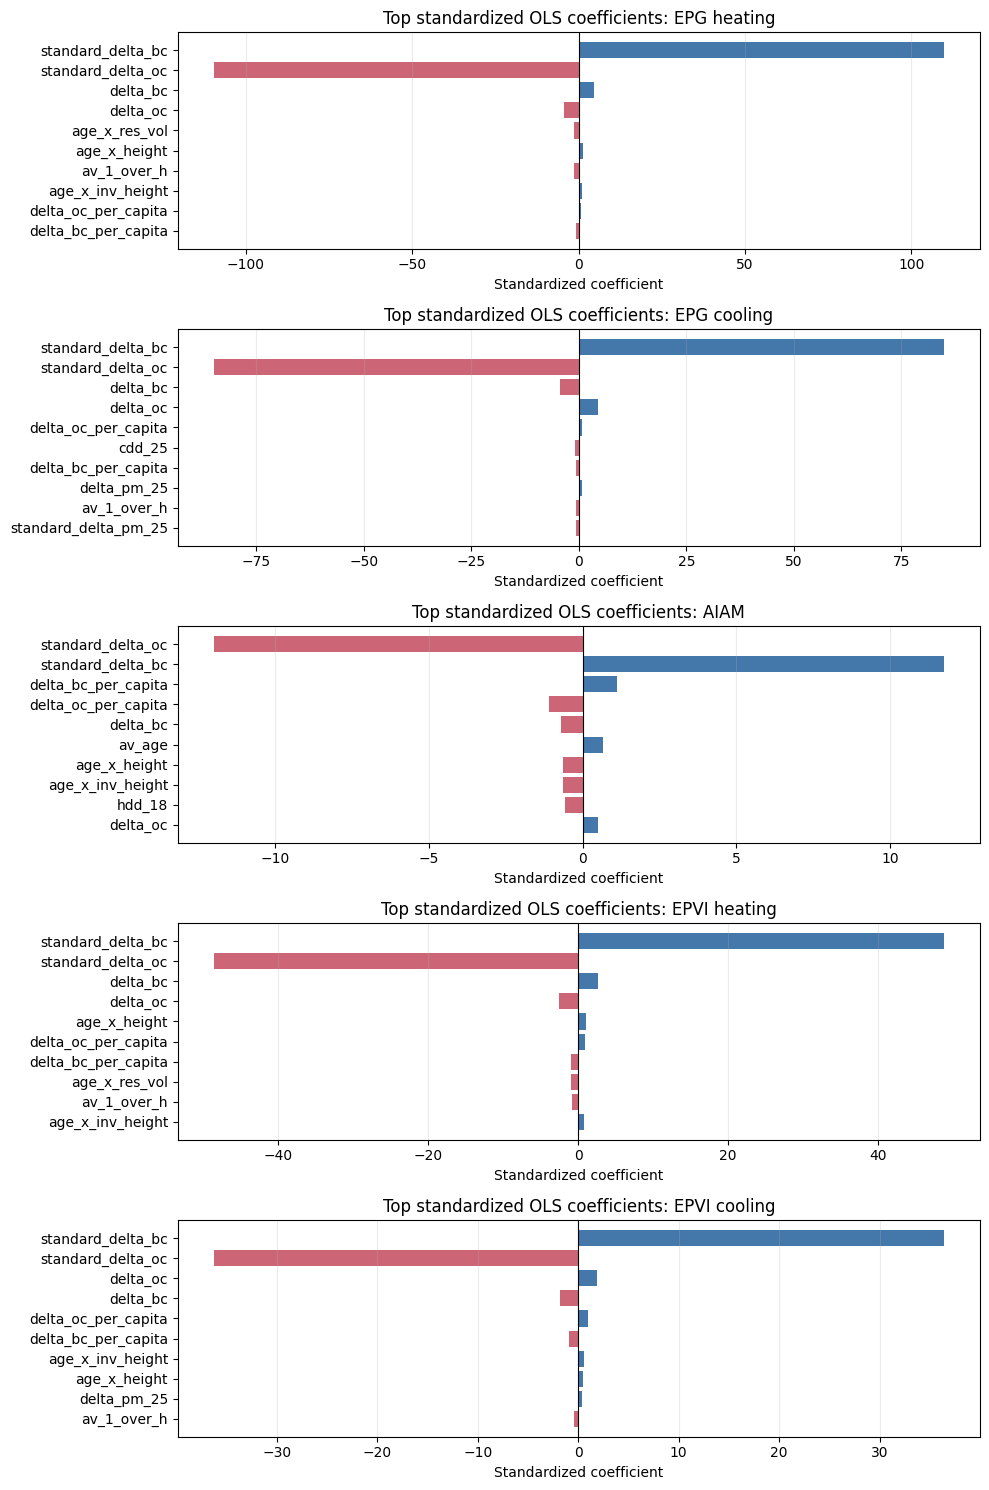

In [7]:
fig, axes = plt.subplots(len(EPVI_TARGETS), 1, figsize=(10, 3.0 * len(EPVI_TARGETS)), squeeze=False)
for ax, target in zip(axes[:, 0], EPVI_TARGETS):
    top = coef_df.loc[coef_df["target"].eq(target)].head(10).iloc[::-1]
    colors = np.where(top["standardized_coef"] >= 0, "#4477AA", "#CC6677")
    ax.barh(top["feature"], top["standardized_coef"], color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Top standardized OLS coefficients: {target}")
    ax.set_xlabel("Standardized coefficient")
    ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## Observed vs Predicted Diagnostics

These plots compare spatial-CV predictions on training regions and final predictions on the fixed test set. Strong train performance with weak spatial-CV/test performance indicates spatial transfer problems rather than simple linear fit quality.


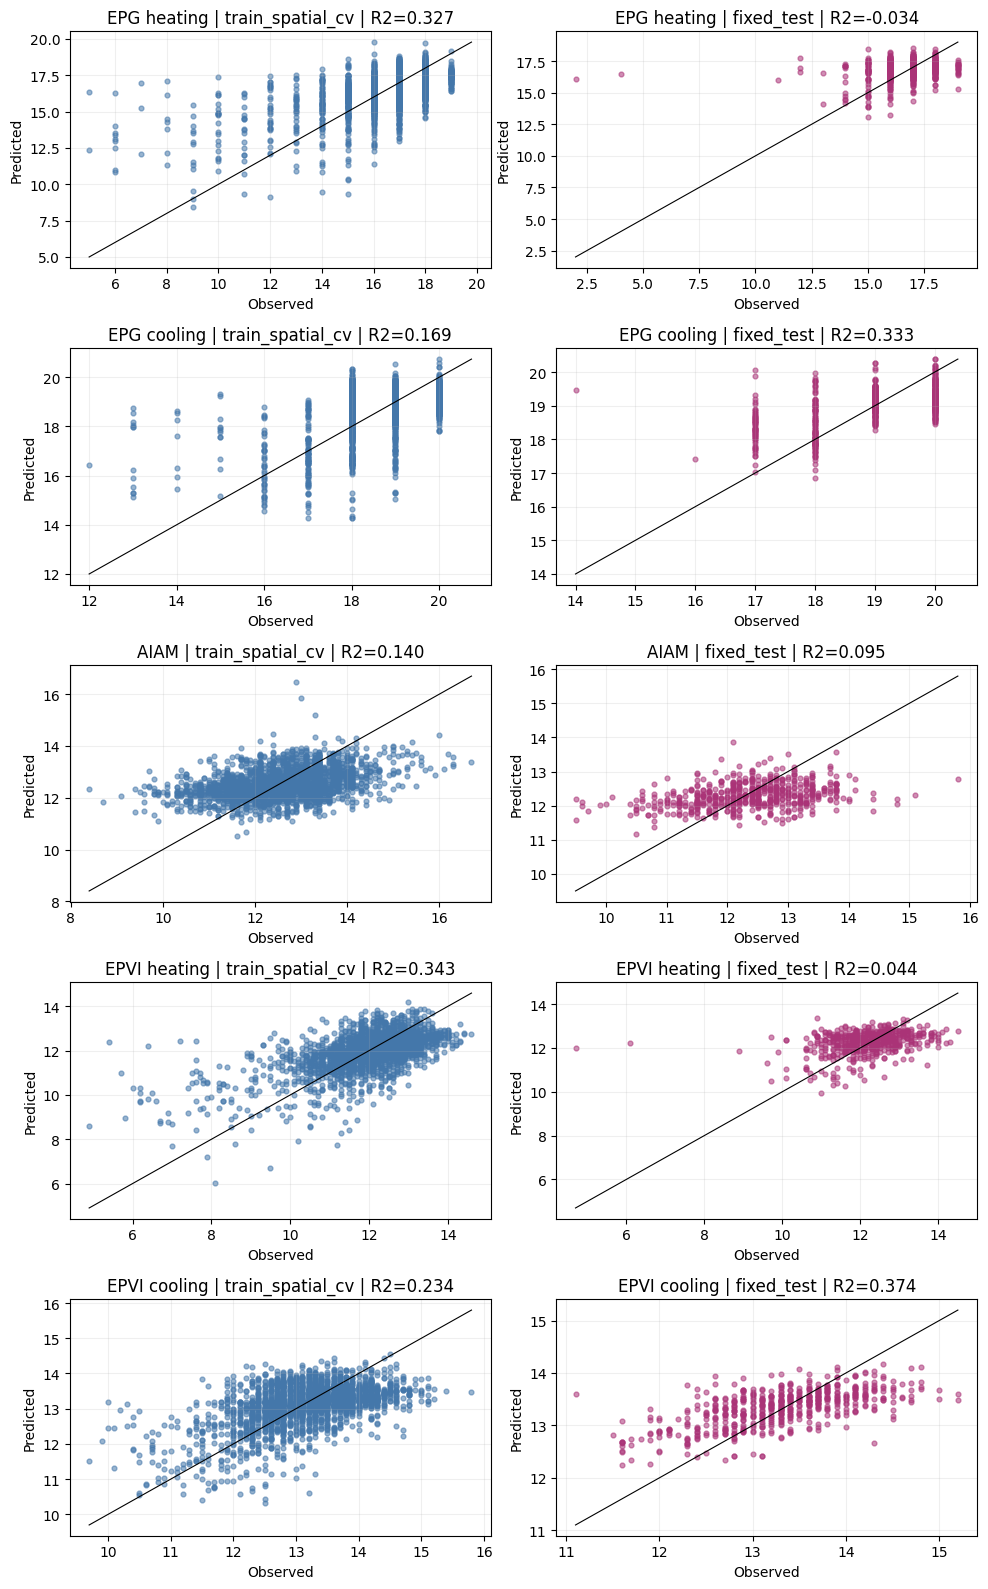

In [8]:
fig, axes = plt.subplots(len(EPVI_TARGETS), 2, figsize=(10, 3.2 * len(EPVI_TARGETS)), squeeze=False)
for row_idx, target in enumerate(EPVI_TARGETS):
    for col_idx, role in enumerate(["train_spatial_cv", "fixed_test"]):
        ax = axes[row_idx, col_idx]
        part = predictions_df.loc[
            predictions_df["target"].eq(target) & predictions_df["prediction_role"].eq(role)
        ]
        ax.scatter(part["observed"], part["predicted"], s=12, alpha=0.55, color="#4477AA" if role == "train_spatial_cv" else "#AA3377")
        lo = min(part["observed"].min(), part["predicted"].min())
        hi = max(part["observed"].max(), part["predicted"].max())
        ax.plot([lo, hi], [lo, hi], color="black", linewidth=0.8)
        r2 = r2_score(part["observed"], part["predicted"])
        ax.set_title(f"{target} | {role} | R2={r2:.3f}")
        ax.set_xlabel("Observed")
        ax.set_ylabel("Predicted")
        ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## Compact Interpretation

Use the cells above to answer three diagnostic questions:

1. How much predictive signal is linearly available in the satellite-derived indices?
2. Does performance survive spatial-CV and fixed-test evaluation?
3. Which constructed indices dominate the linear association, and are these associations plausible or likely proxies for geography?


In [9]:
interpretation_rows = []
for row in metrics_df.itertuples(index=False):
    interpretation_rows.append({
        "target": row.target,
        "train_spatial_cv_r2": row.train_spatial_cv_r2,
        "fixed_test_r2": row.fixed_test_r2,
        "generalization_gap_in_sample_minus_cv": row.train_in_sample_r2 - row.train_spatial_cv_r2,
        "top_positive_index": coef_df.loc[coef_df["target"].eq(row.target)].sort_values("standardized_coef", ascending=False).iloc[0]["feature"],
        "top_negative_index": coef_df.loc[coef_df["target"].eq(row.target)].sort_values("standardized_coef", ascending=True).iloc[0]["feature"],
        "largest_abs_index": coef_df.loc[coef_df["target"].eq(row.target)].iloc[0]["feature"],
    })
interpretation_df = pd.DataFrame(interpretation_rows)
display(interpretation_df)


,target,train_spatial_cv_r2,fixed_test_r2,generalization_gap_in_sample_minus_cv,top_positive_index,top_negative_index,largest_abs_index
0,EPG heating,0.326953,-0.033988,0.143055,standard_delta_bc,standard_delta_oc,standard_delta_bc
1,EPG cooling,0.168752,0.332690,0.324572,standard_delta_bc,standard_delta_oc,standard_delta_bc
2,AIAM,0.139735,0.095251,0.128686,standard_delta_bc,standard_delta_oc,standard_delta_oc
3,EPVI heating,0.343475,0.043622,0.146501,standard_delta_bc,standard_delta_oc,standard_delta_bc
4,EPVI cooling,0.233606,0.373809,0.203089,standard_delta_bc,standard_delta_oc,standard_delta_bc
